Olá, Maria Clara!

Meu nome é Alan e estou feliz em revisar seu projeto hoje!

Quando eu identificar um erro pela primeira vez, apenas o apontarei. A ideia é que você tente identificá-lo e corrigi-lo por conta própria. Ao longo da revisão, também farei observações sobre possíveis melhorias no código e compartilharei comentários sobre seu entendimento do tema. Caso encontre dificuldades para resolver algum ponto, na próxima iteração fornecerei dicas mais específicas e exemplos práticos para ajudá-la. Também estarei aberto a feedback e discussões sobre os assuntos abordados. Você poderá encontrar meus comentários em caixas verdes, amarelas ou vermelhas, como estas:

<div class="alert alert-block alert-success"><b>Comentário: </b> <a class="tocSkip"></a>Sucesso. Tudo está correto.</div>

<div class="alert alert-block alert-warning"><b>Comentário: </b> <a class="tocSkip"></a>Observações. Algumas recomendações.</div>

<div class="alert alert-block alert-danger"><b>Comentário: </b> <a class="tocSkip"></a>O bloco requer algumas correções. O trabalho não pode ser aceito com os comentários vermelhos.</div>

Você pode me responder usando isto:

<div class="alert alert-block alert-info"><b>Resposta do aluno    </b><a class="tocSkip"></a></div>

<div class="alert alert-block alert-success">
<b>Comentário geral do revisor: </b> <a class="tocSkip"></a>

Olá, Maria Clara! Obrigado pelo envio. Projeto de teste A/B muito completo e bem interpretado: você tratou os três arquivos (inclusive corrigindo o separador de hypotheses e removendo os 58 usuários presentes nos dois grupos), comparou ICE e RICE com a explicação da mudança de ordem, construiu as curvas acumuladas de receita, ticket médio e conversão com as diferenças relativas — cada uma com uma leitura escrita cuidadosa —, identificou as anomalias por percentis e aplicou Mann-Whitney para conversão e ticket nos dados brutos e filtrados, chegando a uma decisão final consistente. Os resultados conferem com o esperado.

Comentei cada seção. O projeto está aprovado. Parabéns pelo trabalho.
</div>

# 1. Importação das bibliotecas

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st

# 2. Carregamento dos dados e exploração inicial

In [2]:
hypotheses = pd.read_csv('/datasets/hypotheses_us.csv')
orders = pd.read_csv('/datasets/orders_us.csv')
visits = pd.read_csv('/datasets/visits_us.csv')

In [3]:

display(hypotheses.info())
display(hypotheses.head())


display(orders.info())
display(orders.head())


display(visits.info())
display(visits.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 1 columns):
 #   Column                                     Non-Null Count  Dtype 
---  ------                                     --------------  ----- 
 0   Hypothesis;Reach;Impact;Confidence;Effort  9 non-null      object
dtypes: object(1)
memory usage: 200.0+ bytes


None

,Hypothesis;Reach;Impact;Confidence;Effort
0,Add two new channels for attracting traffic. T...
1,Launch your own delivery service. This will sh...
2,Add product recommendation blocks to the store...
3,Change the category structure. This will incre...
4,Change the background color on the main page. ...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   transactionId  1197 non-null   int64  
 1   visitorId      1197 non-null   int64  
 2   date           1197 non-null   object 
 3   revenue        1197 non-null   float64
 4   group          1197 non-null   object 
dtypes: float64(1), int64(2), object(2)
memory usage: 46.9+ KB


None

,transactionId,visitorId,date,revenue,group
0,3667963787,3312258926,2019-08-15,30.4,B
1,2804400009,3642806036,2019-08-15,15.2,B
2,2961555356,4069496402,2019-08-15,10.2,A
3,3797467345,1196621759,2019-08-15,155.1,B
4,2282983706,2322279887,2019-08-15,40.5,B


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   date    62 non-null     object
 1   group   62 non-null     object
 2   visits  62 non-null     int64 
dtypes: int64(1), object(2)
memory usage: 1.6+ KB


None

,date,group,visits
0,2019-08-01,A,719
1,2019-08-02,A,619
2,2019-08-03,A,507
3,2019-08-04,A,717
4,2019-08-05,A,756


# 3. Limpeza e pré-processamento dos dados

In [4]:

# Carregamento de hypotheses tendo em conta o separador (;)
hypotheses = pd.read_csv('/datasets/hypotheses_us.csv', sep=';')


In [5]:
# Padronização dos nomes de todas as colunas para minúsculas
hypotheses.columns = hypotheses.columns.str.lower()
orders.columns = orders.columns.str.lower()
visits.columns = visits.columns.str.lower()

In [6]:

# Conversão das colunas de data para o formato datetime
orders['date'] = pd.to_datetime(orders['date'])
visits['date'] = pd.to_datetime(visits['date'])


In [7]:

# Lista de utilizadores do grupo A e do grupo B
users_a = orders[orders['group'] == 'A']['visitorid']
users_b = orders[orders['group'] == 'B']['visitorid']

# Identificação de utilizadores que estão no grupo A e no gruo B
overlap_users = users_a[users_a.isin(users_b)].unique()

print(f"Utilizadores encontrados em ambos os grupos A e B: {len(overlap_users)}")


Utilizadores encontrados em ambos os grupos A e B: 58


In [8]:
# Remoção dos  utilizadores que estão em ambos os grupos de 'orders'
orders_clean = orders[~orders['visitorid'].isin(overlap_users)].copy()

print(f"Total de pedidos originais: {len(orders)}")
print(f"Total de pedidos após limpeza: {len(orders_clean)}")

Total de pedidos originais: 1197
Total de pedidos após limpeza: 1016


In [9]:

# Confirmação das alterações de hypotheses
display(hypotheses.head())
hypotheses.info()


,hypothesis,reach,impact,confidence,effort
0,Add two new channels for attracting traffic. T...,3,10,8,6
1,Launch your own delivery service. This will sh...,2,5,4,10
2,Add product recommendation blocks to the store...,8,3,7,3
3,Change the category structure. This will incre...,8,3,3,8
4,Change the background color on the main page. ...,3,1,1,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   hypothesis  9 non-null      object
 1   reach       9 non-null      int64 
 2   impact      9 non-null      int64 
 3   confidence  9 non-null      int64 
 4   effort      9 non-null      int64 
dtypes: int64(4), object(1)
memory usage: 488.0+ bytes


In [10]:
# Confirmação das alterações em orders
display(orders.head())
orders.info()

,transactionid,visitorid,date,revenue,group
0,3667963787,3312258926,2019-08-15,30.4,B
1,2804400009,3642806036,2019-08-15,15.2,B
2,2961555356,4069496402,2019-08-15,10.2,A
3,3797467345,1196621759,2019-08-15,155.1,B
4,2282983706,2322279887,2019-08-15,40.5,B


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   transactionid  1197 non-null   int64         
 1   visitorid      1197 non-null   int64         
 2   date           1197 non-null   datetime64[ns]
 3   revenue        1197 non-null   float64       
 4   group          1197 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(1)
memory usage: 46.9+ KB


In [11]:
# Confirmação das alterações em visits
display(visits.head())
visits.info()

,date,group,visits
0,2019-08-01,A,719
1,2019-08-02,A,619
2,2019-08-03,A,507
3,2019-08-04,A,717
4,2019-08-05,A,756


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    62 non-null     datetime64[ns]
 1   group   62 non-null     object        
 2   visits  62 non-null     int64         
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 1.6+ KB



#### Observações
Após efetuar o carregamento dos dados, fez-se uma análise exploratória. 
Identificou-se a necessidadede recarregar o arquivo 'hipotheses', tendo em conta o separador ponto e vírgula (;).
Verificou-se também que existiam em todos os DataFrames colunas com letras maiúsculas e minúsculas, o que pode gerar erros. Optou-se então, pela alteração dos nomes das colunas, passando a conter só minúsculas.
Verificou-se também que as colunas 'date' de orders e visits continham dados do tipo object. Efetuou-se a alteração necessária, convertendo em datetime.
Observou-se ainda que, tal como sugeria o enunciado, existiam visitantes nos grupos A e B de orders. Efetuou-se a remoção destes utilizadores sobrepostos para não comprometer a validade do teste A/B.

<div class="alert alert-block alert-success">
<b>Comentário do revisor: </b> <a class="tocSkip"></a>

Boa preparação e documentação: você percebeu que hypotheses precisava do separador ';' e recarregou, padronizou os nomes das colunas em minúsculas, converteu as datas para datetime e identificou e removeu os 58 usuários presentes nos dois grupos — cuidado essencial para não contaminar o teste A/B.
</div>

# 4. Priorização de Hipóteses

In [12]:

# ICE
hypotheses['ICE'] = (hypotheses['impact']*hypotheses['confidence'])/hypotheses['effort']
display(hypotheses[['hypothesis', 'ICE']].sort_values(by='ICE', ascending=False))


,hypothesis,ICE
8,Launch a promotion that gives users discounts ...,16.200000
0,Add two new channels for attracting traffic. T...,13.333333
7,Add a subscription form to all the main pages....,11.200000
6,Show banners with current offers and sales on ...,8.000000
2,Add product recommendation blocks to the store...,7.000000
1,Launch your own delivery service. This will sh...,2.000000
5,Add a customer review page. This will increase...,1.333333
3,Change the category structure. This will incre...,1.125000
4,Change the background color on the main page. ...,1.000000


In [13]:

# RICE
hypotheses['RICE'] = (hypotheses['reach']*hypotheses['impact']*hypotheses['confidence'])/hypotheses['effort']
display(hypotheses[['hypothesis', 'RICE','reach']].sort_values(by='RICE', ascending=False))


,hypothesis,RICE,reach
7,Add a subscription form to all the main pages....,112.0,10
2,Add product recommendation blocks to the store...,56.0,8
0,Add two new channels for attracting traffic. T...,40.0,3
6,Show banners with current offers and sales on ...,40.0,5
8,Launch a promotion that gives users discounts ...,16.2,1
3,Change the category structure. This will incre...,9.0,8
1,Launch your own delivery service. This will sh...,4.0,2
5,Add a customer review page. This will increase...,4.0,3
4,Change the background color on the main page. ...,3.0,3


#### Observações

  As três principais hipóteses pelo framework ICE são a 8, a 0 e a 7. O ICE foca-se puramente no impacto e na confiança em relação ao esforço necessário, sem considerar quantos utilizadores sofrerão o impacto da alteração.

  Ao aplicar o framework RICE, a hipótese 7 sobe para o 1.º lugar, alcançando uma pontuação massiva de 112.0 (muito superior à segunda colocada, a hipótese 2, com 56.0).

  A alteração na ordenação ocorre devido à variável Reach (Alcance):
  * A Hipótese 7 ("Adicionar formulário de subscrição a todas as páginas principais") tem um parâmetro de alcance máximo (Reach = 10), pois afeta praticamente 100% dos visitantes do site. Isto multiplica significativamente a sua pontuação no RICE.
  * Em contrapartida, a Hipótese 8 (descontos), apesar de ter elevado impacto e confiança no ICE, tem um alcance baixo (Reach = 1), o que a faz cair para a 5.ª posição quando avaliamos o retorno global para o negócio.

Tendo em conta estes resultados, a hipótese 7 deve ser a prioridade número 1 para o teste A/B.


<div class="alert alert-block alert-success">
<b>Comentário do revisor: </b> <a class="tocSkip"></a>

Priorização correta: a hipótese 8 lidera no ICE e a hipótese 7 assume o topo no RICE por causa do Reach. Sua explicação de por que a ordem muda (o alcance máximo da hipótese 7 contra o alcance baixo da 8) está clara e certa.
</div>

# 5. Análise do Teste A/B

In [14]:

# Criação de uma matriz com pares únicos de datas e grupos
datesGroups = orders_clean[['date', 'group']].drop_duplicates()

# Obtenção de dados acumulados diários sobre pedidos
ordersAggregated = datesGroups.apply(
    lambda x: orders_clean[
        (orders_clean['date'] <= x['date']) & (orders_clean['group'] == x['group'])
    ].agg({
        'date': 'max',
        'group': 'max',
        'transactionid': 'nunique',
        'visitorid': 'nunique',
        'revenue': 'sum'
    }),
    axis=1
).sort_values(by=['date', 'group']).reset_index(drop=True)

# Obtenção de dados acumulados diários sobre visitas (FALTA ESTE PASSO!)
visitsAggregated = datesGroups.apply(
    lambda x: visits[
        (visits['date'] <= x['date']) & (visits['group'] == x['group'])
    ].agg({
        'date': 'max',
        'group': 'max',
        'visits': 'sum'
    }),
    axis=1
).sort_values(by=['date', 'group']).reset_index(drop=True)

# Junção das 2 tabelas
cumulativeData = ordersAggregated.merge(
    visitsAggregated, 
    left_on=['date', 'group'], 
    right_on=['date', 'group']
)

# Alteração dos nomes das colunas e separação por grupo
cumulativeData.columns = ['date', 'group', 'orders', 'buyers', 'revenue', 'visits']
cumulativeRevenueA = cumulativeData[cumulativeData['group'] == 'A']
cumulativeRevenueB = cumulativeData[cumulativeData['group'] == 'B']

# Confirmação do resultado
display(cumulativeData.head(10))


,date,group,orders,buyers,revenue,visits
0,2019-08-01,A,23,19,2266.6,719
1,2019-08-01,B,17,17,967.2,713
2,2019-08-02,A,42,36,3734.9,1338
3,2019-08-02,B,40,39,3535.3,1294
4,2019-08-03,A,66,60,5550.1,1845
5,2019-08-03,B,54,53,4606.9,1803
6,2019-08-04,A,77,71,6225.6,2562
7,2019-08-04,B,68,66,6138.5,2573
8,2019-08-05,A,99,92,7623.6,3318
9,2019-08-05,B,89,87,7587.8,3280


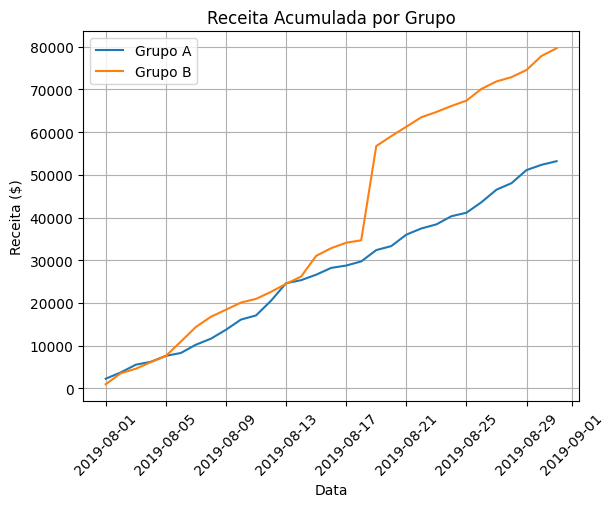

In [15]:
plt.plot(cumulativeRevenueA['date'], cumulativeRevenueA['revenue'], label='Grupo A')
plt.plot(cumulativeRevenueB['date'], cumulativeRevenueB['revenue'], label='Grupo B')

plt.title('Receita Acumulada por Grupo')
plt.xlabel('Data')
plt.ylabel('Receita ($)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.show()

#### Observações

Ao longo de quase todo o mês, a receita de ambos os grupos cresceu de forma constante e semelhante, com o Grupo B a liderar ligeiramente a partir de 5 de agosto.
No dia 18 de agosto, há um salto vertiginoso e repentino na receita do Grupo B.
Um salto desta magnitude num único dia não reflete uma mudança gradual no comportamento dos utilizadores, mas sim a ocorrência de pedidos anómalos de valor extremamente elevado (outliers) ou um pico repentino no número de compras.
Após este pico, ambos os grupos continuam a crescer a um ritmo paralelo e constante até ao final do mês.

<div class="alert alert-block alert-success">
<b>Comentário do revisor: </b> <a class="tocSkip"></a>

Boa a receita acumulada por grupo, com a leitura de que o grupo B se descola no dia 18 e a hipótese correta de que isso vem de pedidos anômalos de valor muito alto — exatamente o cuidado que a análise pede antes de concluir.
</div>

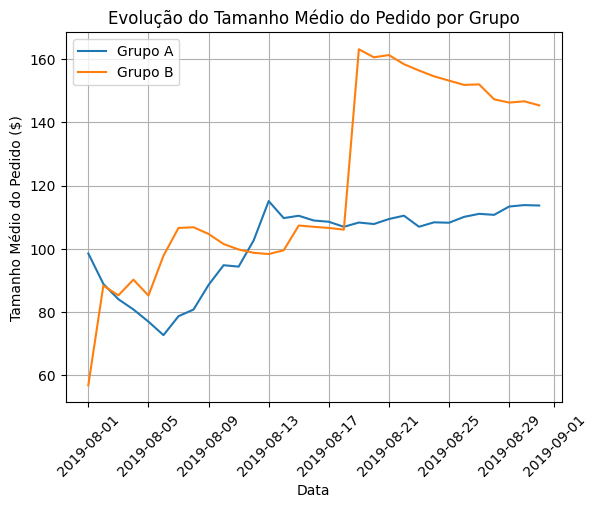

In [16]:
# Cálculo da evolução do tamanho médio do pedido (Receita / Pedidos) para cada grupo
plt.plot(cumulativeRevenueA['date'], cumulativeRevenueA['revenue'] / cumulativeRevenueA['orders'], label='Grupo A')
plt.plot(cumulativeRevenueB['date'], cumulativeRevenueB['revenue'] / cumulativeRevenueB['orders'], label='Grupo B')

plt.title('Evolução do Tamanho Médio do Pedido por Grupo')
plt.xlabel('Data')
plt.ylabel('Tamanho Médio do Pedido ($)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.show()


#### Observações

Na primeira metade do mês, o tamanho médio dos pedidos flutuou bastante em ambos os grupos. O Grupo A começou em cerca de 100 USD, caiu para perto de 73 USD no dia 6 e subiu até 115 USD no dia 13. O Grupo B começou mais baixo (perto de 57 USD) e subiu até rondar os 100-105 USD.
No dia 18-19 de agosto, o  Grupo B tem uma grande subida, disparando de 107 USD para mais de 160 USD num único dia.
*Este aumento repentino e massivo indica fortemente a presença de pedidos anómalos de valor muito elevado (outliers) efetuados no Grupo B nessa data.
Após o dia 19, o tamanho médio dos pedidos do Grupo B começa a cair suavemente e a estabilizar (terminando perto de 145 USD), enquanto o Grupo A estabiliza e mantém uma trajetória constante a rondar os 110-115 USD.

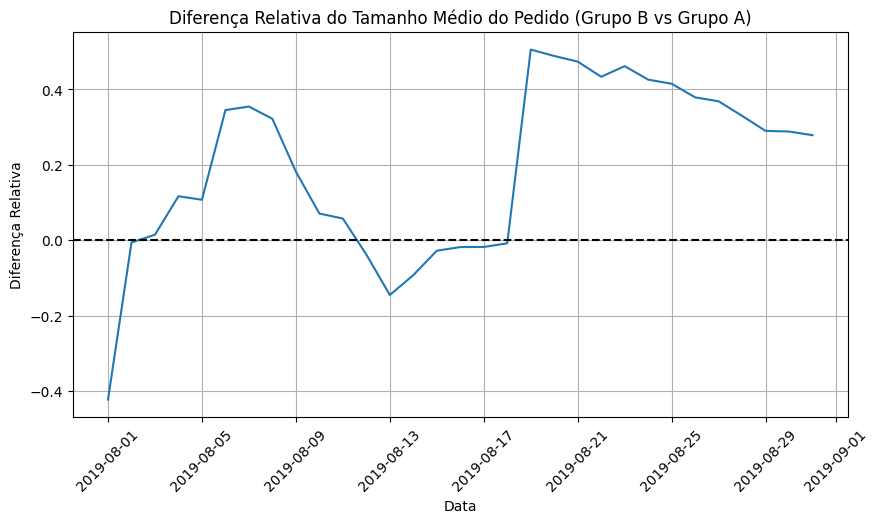

In [17]:
plt.figure(figsize=(10, 5))

ticket_A = cumulativeRevenueA['revenue'] / cumulativeRevenueA['orders']
ticket_B = cumulativeRevenueB['revenue'] / cumulativeRevenueB['orders']

# Cálculo ddiferença relativa
plt.plot(
    cumulativeRevenueA['date'], 
    (ticket_B.values / ticket_A.values) - 1
)

#  Linha de referência no zero (B = A)
plt.axhline(y=0, color='black', linestyle='--')

plt.title('Diferença Relativa do Tamanho Médio do Pedido (Grupo B vs Grupo A)')
plt.xlabel('Data')
plt.ylabel('Diferença Relativa')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

#### Observações
O gráfico da diferença relativa apresenta grandes oscilações ao longo de quase todo o período do teste.
O Grupo B começou significativamente abaixo do Grupo A, recuperou até atingir um pico positivo de quase +35%, voltou a cair para terreno negativo perto de meados de agosto (-15%) e recuperou ligeiramente até ao dia 18.
No dia 18-19 de agosto, a diferença disparou abruptamente para mais de +50% a favor do Grupo B (efeito do outlier). 
Após esse pico, a linha começa a declinar suavemente (terminando perto dos +30%), o que sugere que o valor médio do Grupo B está a "diluir-se" à medida que mais pedidos normais entram, confirmando que o salto inicial se deveu a grandes compras pontuais (*outliers*).

<div class="alert alert-block alert-success">
<b>Comentário do revisor: </b> <a class="tocSkip"></a>

Bom: o ticket médio acumulado e sua diferença relativa mostram a oscilação inicial e o salto do grupo B no dia 18, e você já sinaliza que a diferença 'se dilui' com a entrada de pedidos normais, confirmando a influência dos outliers.
</div>

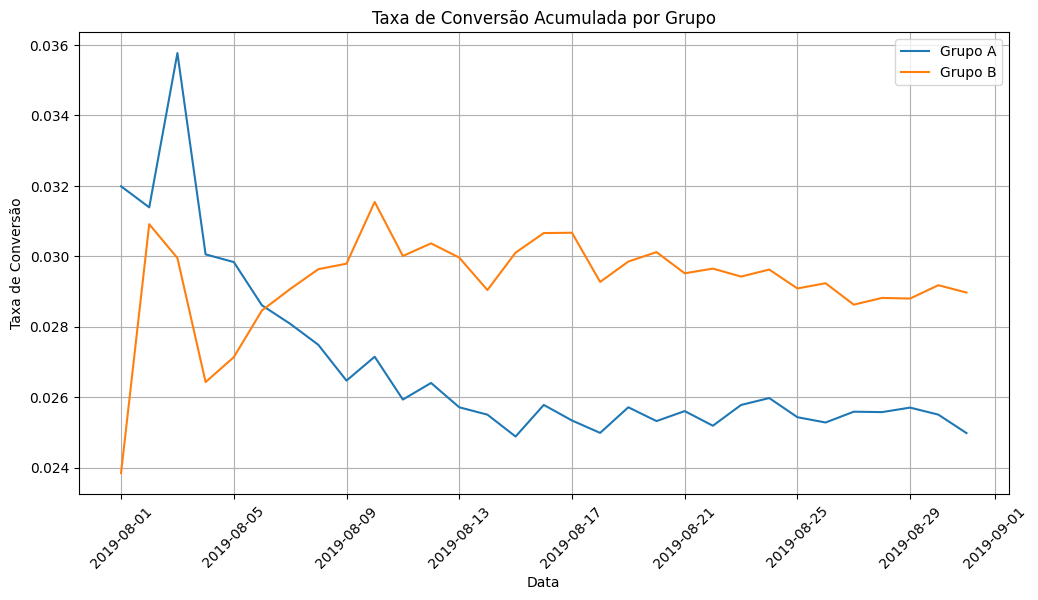

In [18]:

plt.figure(figsize=(12, 6))

# Desenho do gráfico (taxa de conversão = orders / visits)
plt.plot(
    cumulativeRevenueA['date'], 
    cumulativeRevenueA['orders'] / cumulativeRevenueA['visits'], 
    label='Grupo A'
)
plt.plot(
    cumulativeRevenueB['date'], 
    cumulativeRevenueB['orders'] / cumulativeRevenueB['visits'], 
    label='Grupo B'
)

plt.title('Taxa de Conversão Acumulada por Grupo')
plt.xlabel('Data')
plt.ylabel('Taxa de Conversão')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.show()

#### Observações
Nos primeiros dias do mês (até cerca de 5 de agosto), as taxas de conversão de ambos os grupos apresentaram uma forte oscilação. O Grupo A teve um pico inicial próximo dos 3.6% (0.036), enquanto o Grupo B começou mais baixo, perto de 2.4% (0.024).
A partir de 6 de agosto, ocorre uma inversão clara. A taxa de conversão do Grupo A começou a declinar, enquanto a do Grupo B subiu. O Grupo B assumiu a liderança e manteve-se consistentemente acima do Grupo A até ao final do mês.
A partir de meados do mês (cerca de 17-18 de agosto), as taxas de conversão de ambos os grupos estabilizaram:
  * O Grupo B estabilizou numa taxa de conversão entre 2.9% e 3.0% (0.029 - 0.030).
  * O Grupo A estabilizou num nível inferior, entre 2.5% e 2.6% (0.025 - 0.026).


As alterações implementadas no Grupo B foram bem-sucedidas em converter uma maior proporção de visitantes em compradores reais.
Ao contrário dos gráficos de receita e ticket médio (onde ocorreu um salto abrupto no dia 18 devido a outliers), a taxa de conversão do Grupo B manteve-se constante e sem picos isolados. Isto demonstra que o ganho de conversão no Grupo B é sólido e sustentável, não dependendo de compras atípicas.

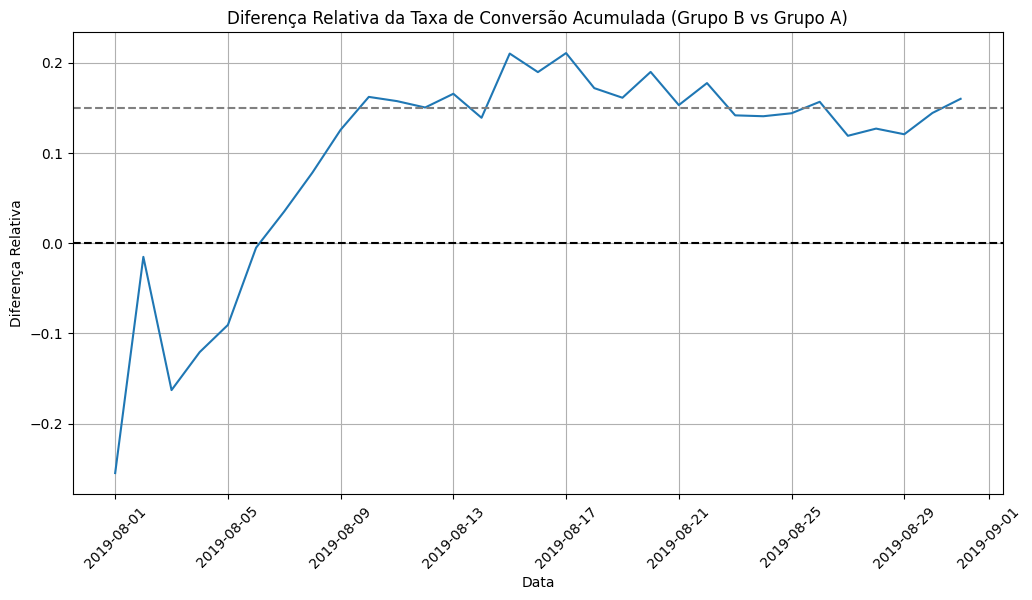

In [19]:
plt.figure(figsize=(12, 6))

# Cálculo da taxa de conversão para cada grupo
conversion_A = cumulativeRevenueA['orders'] / cumulativeRevenueA['visits']
conversion_B = cumulativeRevenueB['orders'] / cumulativeRevenueB['visits']

# Diferença relativa (B vs A)
plt.plot(
    cumulativeRevenueA['date'], 
    (conversion_B.values / conversion_A.values) - 1
)

# Adição de linha no zero   na média (~15%)
plt.axhline(y=0, color='black', linestyle='--')
plt.axhline(y=0.15, color='grey', linestyle='--')

plt.title('Diferença Relativa da Taxa de Conversão Acumulada (Grupo B vs Grupo A)')
plt.xlabel('Data')
plt.ylabel('Diferença Relativa')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

#### Observações
Nos primeiros dias (1 a 5 de agosto), o Grupo B esteve em desvantagem em relação ao Grupo A, atingindo um ponto crítico próximo dos -25%.
A partir do dia 6 de agosto, a conversão do Grupo B recuperou rapidamente, cruzando a linha do zero e mantendo-se continuamente em território positivo.
Atingiu um pico máximo superior a +20% por volta do dia 15-17 de agosto. A partir daí, a curva estabilizou suavemente em torno da linha de referência dos 15%, terminando o mês com uma vantagem perto desse valor.

O Grupo B estabeleceu uma vantagem clara e sustentada sobre o Grupo A a partir da segunda semana do teste.
O facto de a linha ter estabilizado num patamar positivo (~15%) no final do período indica que a métrica se encontra madura, confirmando que a alteração no Grupo B trouxe uma melhoria real no funil de conversão e não apenas uma flutuação aleatória.

<div class="alert alert-block alert-success">
<b>Comentário do revisor: </b> <a class="tocSkip"></a>

Boa análise da conversão acumulada e da diferença relativa: você observa que o grupo B se estabiliza numa vantagem em torno de +15% e destaca que, ao contrário da receita, a conversão não teve picos isolados — evidência de um ganho sólido e não dependente de compras atípicas.
</div>

In [20]:
orders_per_user = (
    orders_clean.groupby('visitorid', as_index=False)
    .agg({'transactionid': 'nunique'})
    .rename(columns={'transactionid': 'orders'})
)

# Cálculo dos percentis 95 e 99
percentiles_orders = np.percentile(orders_per_user['orders'], [95, 99])

print(f"Percentil 95 do número de pedidos por utilizador: {percentiles_orders[0]:.0f}")
print(f"Percentil 99 do número de pedidos por utilizador: {percentiles_orders[1]:.0f}")

Percentil 95 do número de pedidos por utilizador: 1
Percentil 99 do número de pedidos por utilizador: 2


#### Análise do Número de Pedidos por Utilizador:

* **Percentil 95:** 95% dos utilizadores fizeram no máximo 1 pedido.
* **Percentil 99:** Apenas 1% dos utilizadores fizeram mais de 2 pedidos.

#### Definição do Ponto de Anomalia:
Com base nestes dados, adotamos o percentil 95 como critério limite. Qualquer utilizador que tenha efetuado mais de 1 pedido será considerado uma anomalia (outlier) e filtrado nas análises de dados limpos.

<div class="alert alert-block alert-success">
<b>Comentário do revisor: </b> <a class="tocSkip"></a>

Correto: os percentis 95 e 99 dos pedidos por usuário (1 e 2) embasam bem o critério de anomalia (mais de 1 pedido).
</div>

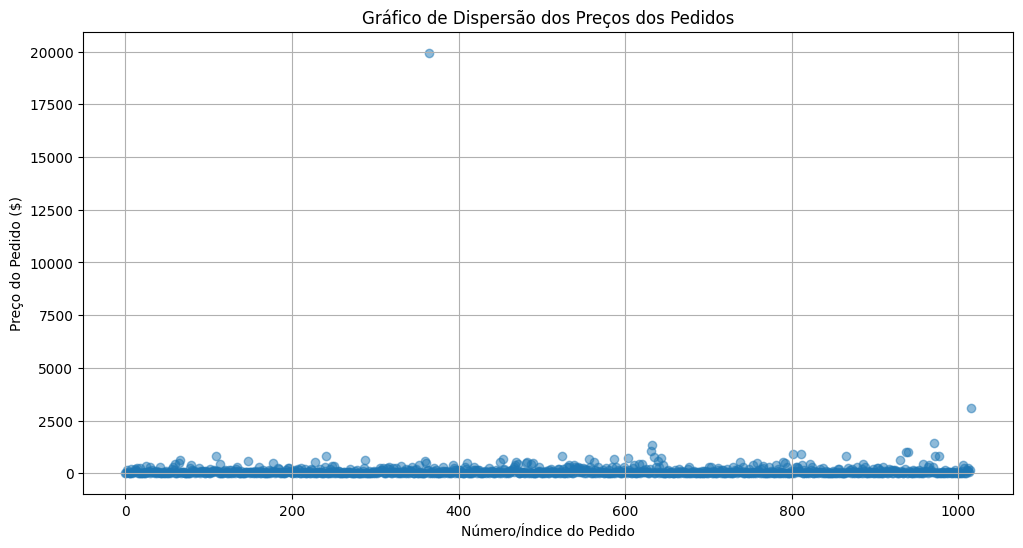

In [21]:
plt.figure(figsize=(12, 6))

x_values = pd.Series(range(0, len(orders_clean['revenue'])))

# Desenho do gráfico de dispersão
plt.scatter(x_values, orders_clean['revenue'], alpha=0.5)

plt.title('Gráfico de Dispersão dos Preços dos Pedidos')
plt.xlabel('Número/Índice do Pedido')
plt.ylabel('Preço do Pedido ($)')
plt.grid(True)
plt.show()

#### Observações
A esmagadora maioria dos pedidos encontra-se concentrada na base do gráfico, com valores significativamente inferiores a $1.000.
Identificam-se claramente dois pontos atípicos muito afastados da distribuição normal:
  * Um pedido isolado em torno dos $3.000.
  * Um pedido colossal a atingir os $20.000.

Este pedido de $20.000 explica perfeitamente o salto brusco e desproporcional que observámos anteriormente nos gráficos de receita acumulada e ticket médio do Grupo B por volta do dia 18 de agosto.
Um único valor atípico desta magnitude distorce gravemente as médias e as métricas acumuladas do grupo. 
Para garantir uma comparação coerente no Teste A/B, é necessário calcular os percentis (95 e 99) do valor das compras para definir um limite de corte realista e filtrar estes outliers.

<div class="alert alert-block alert-success">
<b>Comentário do revisor: </b> <a class="tocSkip"></a>

Boa a dispersão dos preços dos pedidos: a concentração em valores baixos e os outliers (um perto de 3.000 e o de 20.000) ficam evidentes, e você conecta o pedido de 20.000 ao salto observado na receita/ticket do grupo B no dia 18.
</div>

In [22]:
# Cálculo dos percentis 95 e 99 dos preços dos pedidos
percentiles_revenue = np.percentile(orders_clean['revenue'], [95, 99])

print(f"Percentil 95 do preço dos pedidos: ${percentiles_revenue[0]:.2f}")
print(f"Percentil 99 do preço dos pedidos: ${percentiles_revenue[1]:.2f}")

Percentil 95 do preço dos pedidos: $414.27
Percentil 99 do preço dos pedidos: $830.30


#### Análise dos Percentis dos Preços dos Pedidos:

* **Percentil 95:** 95% de todos os pedidos tiveram um valor de até $414.27. Apenas 5% dos pedidos custaram mais do que este valor.
* **Percentil 99:** Apenas 1% dos pedidos tiveram um valor superior a $830.30.

#### Definição do Ponto de Anomalia:
Definimos o percentil 95 como o nosso limite de corte para anomalias de valor. Assim, qualquer pedido com um valor superior a $414.27 será considerado uma anomalia.


#### Resumo dos Critérios de Anomalia Definidos:
 **Número de pedidos:** Utilizadores com mais de 1 pedido.
 
 **Preço do pedido:** Pedidos com valor superior a $414.27.

<div class="alert alert-block alert-success">
<b>Comentário do revisor: </b> <a class="tocSkip"></a>

Correto: os percentis 95 e 99 da receita (414,27 e 830,30) definem o limite de corte, e você resume bem os dois critérios de anomalia (número de pedidos e valor do pedido).
</div>

In [23]:
# Criação de tabelas com o número de pedidos por utilizador para cada grupo
ordersByUsersA = (
    orders_clean[orders_clean['group'] == 'A']
    .groupby('visitorid', as_index=False)
    .agg({'transactionid': 'nunique'})
    .rename(columns={'transactionid': 'orders'})
)

ordersByUsersB = (
    orders_clean[orders_clean['group'] == 'B']
    .groupby('visitorid', as_index=False)
    .agg({'transactionid': 'nunique'})
    .rename(columns={'transactionid': 'orders'})
)


sampleA = pd.concat([
    ordersByUsersA['orders'],
    pd.Series(0, index=np.arange(visits[visits['group'] == 'A']['visits'].sum() - len(ordersByUsersA)), name='orders')
], axis=0)

sampleB = pd.concat([
    ordersByUsersB['orders'],
    pd.Series(0, index=np.arange(visits[visits['group'] == 'B']['visits'].sum() - len(ordersByUsersB)), name='orders')
], axis=0)

# Teste Mann-Whitney U e cálculo do ganho relativo do Grupo B
p_value = st.mannwhitneyu(sampleA, sampleB)[1]
relative_gain = sampleB.mean() / sampleA.mean() - 1

print(f"p-value: {p_value:.5f}")
print(f"Ganho relativo da conversão do Grupo B: {relative_gain:.1%}")

p-value: 0.01102
Ganho relativo da conversão do Grupo B: 16.0%


#### Análise da Significância Estatística da Conversão (Dados Brutos):

* **p-value:** 0.01102 (inferior ao nível de significância de $\alpha = 0.05$).
* **Ganho Relativo do Grupo B:** 16.0%.


Como o $p\text{-value} < 0.05$, rejeitamos a hipótese nula. 
Existe uma diferença estatisticamente significativa na taxa de conversão entre os dois grupos nos dados brutos.
O Grupo B teve um desempenho superior ao Grupo A, obtendo uma taxa de conversão 16.0% maior.
Mesmo considerando a presença de utilizadores anómalos nos dados brutos, o teste confirma estatisticamente que as alterações efetuadas no Grupo B foram eficazes a converter mais visitantes em compradores.

<div class="alert alert-block alert-success">
<b>Comentário do revisor: </b> <a class="tocSkip"></a>

Correto: Mann-Whitney na conversão com os dados brutos dá p~0,011 (< 0,05), então há diferença significativa a favor do grupo B (+16%). Bom uso do teste não paramétrico.
</div>

In [24]:
# Pedidos para o Grupo A e Grupo B
revenue_A = orders_clean[orders_clean['group'] == 'A']['revenue']
revenue_B = orders_clean[orders_clean['group'] == 'B']['revenue']

# Teste Mann-Whitney U
p_value_revenue = st.mannwhitneyu(revenue_A, revenue_B)[1]

# Diferença relativa do ticket médio do Grupo B em relação ao Grupo A
relative_gain_revenue = revenue_B.mean() / revenue_A.mean() - 1

print(f"p-value: {p_value_revenue:.5f}")
print(f"Diferença relativa no ticket médio do Grupo B: {relative_gain_revenue:.1%}")

p-value: 0.86223
Diferença relativa no ticket médio do Grupo B: 27.8%


#### Análise da Significância Estatística do Ticket Médio (Dados Brutos):

* **p-value:** 0.86223 (muito superior ao nível de significância de $\alpha = 0.05$).
* **Diferença Relativa no Ticket Médio (Grupo B):** 27.8%

Como o $p\text{-value} > 0.05$, não há evidência estatística de que exista uma diferença real no tamanho médio dos pedidos entre os dois grupos.
A aparente vantagem de $27.8\%$ no ticket médio do Grupo B é inteiramente provocada por outliers (como o pedido atípico de $20.000$).
O teste A/B no Grupo B funcionou bem para gerar mais vendas (aumentou a conversão), mas não alterou o montante que cada cliente gasta por transação.

<div class="alert alert-block alert-success">
<b>Comentário do revisor: </b> <a class="tocSkip"></a>

Correto: no ticket médio bruto o teste dá p~0,86 (> 0,05), sem diferença significativa, e você atribui a vantagem aparente de 27,8% ao outlier de 20.000. Leitura precisa.
</div>

In [25]:
# Identificação dos utilizadores com mais de 1 pedido (percentil 95)
usersWithManyOrders = pd.concat([
    ordersByUsersA[ordersByUsersA['orders'] > 1]['visitorid'],
    ordersByUsersB[ordersByUsersB['orders'] > 1]['visitorid']
], axis=0)

# Identificação dos utilizadores com pedidos > $414.27 (percentil 95)
usersWithExpensiveOrders = orders_clean[orders_clean['revenue'] > 414.27]['visitorid']

# União e remoção de duplicados dos utilizadores anómalos (abnormalUsers)
abnormalUsers = (
    pd.concat([usersWithManyOrders, usersWithExpensiveOrders], axis=0)
    .drop_duplicates()
    .sort_values()
)

# Criação de amostras limpas (excluindo os abnormalUsers)
sampleA_filtered = pd.concat([
    ordersByUsersA[~ordersByUsersA['visitorid'].isin(abnormalUsers)]['orders'],
    pd.Series(0, index=np.arange(visits[visits['group'] == 'A']['visits'].sum() - len(ordersByUsersA)), name='orders')
], axis=0)

sampleB_filtered = pd.concat([
    ordersByUsersB[~ordersByUsersB['visitorid'].isin(abnormalUsers)]['orders'],
    pd.Series(0, index=np.arange(visits[visits['group'] == 'B']['visits'].sum() - len(ordersByUsersB)), name='orders')
], axis=0)

# Cálculo do p-value e o ganho relativo nos dados filtrados
p_value_conv_filtered = st.mannwhitneyu(sampleA_filtered, sampleB_filtered)[1]
relative_gain_conv_filtered = sampleB_filtered.mean() / sampleA_filtered.mean() - 1

print(f"p-value (dados filtrados): {p_value_conv_filtered:.5f}")
print(f"Ganho relativo da conversão do Grupo B (dados filtrados): {relative_gain_conv_filtered:.1%}")

p-value (dados filtrados): 0.01593
Ganho relativo da conversão do Grupo B (dados filtrados): 17.4%


#### Análise da Significância Estatística da Conversão (Dados Filtrados):

* **p-value (dados filtrados):** 0.01593 (inferior ao nível de significância de $\alpha = 0.05$).
* **Ganho Relativo da Conversão do Grupo B:** 17.4%.

Mesmo após a remoção de todas as anomalias, rejeitamos a hipótese nula ($p\text{-value} < 0.05$). A diferença na taxa de conversão entre os dois grupos é estatisticamente significativa.
O Grupo B superou o Grupo A com uma conversão 17.4% maior nos dados limpos, mostrando que o resultado não depende de utilizadores atípicos.
A alteração testada no Grupo B demonstrou ser amplamente bem-sucedida em transformar visitantes em compradores reais.

<div class="alert alert-block alert-success">
<b>Comentário do revisor: </b> <a class="tocSkip"></a>

Correto: após remover as anomalias, a conversão continua significativa (p~0,016, +17,4%), mostrando que o resultado não depende de usuários atípicos.
</div>

In [26]:
# Filtragem das transações removendo os utilizadores anómalos 
orders_filtered = orders_clean[~orders_clean['visitorid'].isin(abnormalUsers)]

# Separação das receitas limpas por grupo
revenue_A_filtered = orders_filtered[orders_filtered['group'] == 'A']['revenue']
revenue_B_filtered = orders_filtered[orders_filtered['group'] == 'B']['revenue']

# Teste Mann-Whitney U nos dados filtrados
p_value_revenue_filtered = st.mannwhitneyu(revenue_A_filtered, revenue_B_filtered)[1]

# Diferença relativa do ticket médio limpo
relative_gain_revenue_filtered = revenue_B_filtered.mean() / revenue_A_filtered.mean() - 1

print(f"p-value (dados filtrados): {p_value_revenue_filtered:.5f}")
print(f"Diferença relativa no ticket médio do Grupo B (dados filtrados): {relative_gain_revenue_filtered:.1%}")

p-value (dados filtrados): 0.77119
Diferença relativa no ticket médio do Grupo B (dados filtrados): -3.3%


#### Análise da Significância Estatística do Ticket Médio (Dados Filtrados):

* **p-value (dados filtrados):** 0.77119 (muito superior ao nível de significância de $\alpha = 0.05$).
* **Diferença Relativa no Ticket Médio (Grupo B):** -3.3%.

Como o $p\text{-value} > 0.05$, não podemos rejeitar a hipótese nula, ou seja, não existe diferença estatisticamente significativa no tamanho médio do pedido entre o Grupo A e o Grupo B nos dados limpos.
A aparente vantagem de $27.8\%$ que o Grupo B apresentava nos dados brutos desapareceu  com a remoção dos outliers, fixando-se numa variação irrelevante de $-3.3\%$.
Em resumo, a alteração testada aumentou significativamente a conversão (mais pessoas compraram), mas não influenciou o valor médio gasto por compra.

<div class="alert alert-block alert-success">
<b>Comentário do revisor: </b> <a class="tocSkip"></a>

Correto: no ticket filtrado não há diferença significativa (p~0,77) e a diferença relativa cai para -3,3% — a vantagem aparente dos dados brutos desaparece com a remoção dos outliers.
</div>

# 6. Conclusões

#### Resumo dos resultados
1. **Taxa de Conversão:**
   * **Dados Brutos:** O Grupo B teve uma conversão **16.0% superior** ao Grupo A ($p\text{-value} = 0.01102$).
   * **Dados Filtrados:** Após a remoção das anomalias, o Grupo B manteve uma vantagem estatisticamente significativa com uma conversão **17.4% superior** ($p\text{-value} = 0.01593$).

2. **Tamanho Médio do Pedido (Ticket Médio):**
   * **Dados Brutos:** O Grupo B apresentou uma vantagem aparente de $27.8\%$, mas sem significância estatística ($p\text{-value} = 0.86223$), fruto de um *outlier* pontual de $\$20.000$.
   * **Dados Filtrados:** Com a remoção dos *outliers*, confirmou-se que **não há diferença estatisticamente significativa** no ticket médio entre os dois grupos ($p\text{-value} = 0.77119$, variação de $-3.3\%$).


#### Decisão Final:
OPÇÃO 1: Parar o teste e considerar o Grupo B o líder.

#### Justificação:
A alteração testada na versão B cumpriu com sucesso o objetivo principal de aumentar a taxa de conversão do site em 17.4% de forma estatisticamente comprovada. Embora não tenha alterado o valor gasto por transação, o aumento substancial na quantidade de compradores gera um crescimento direto e real na receita global da empresa. Dado que a diferença na conversão já estabilizou e foi estatisticamente validada, não há necessidade de continuar a recolher dados.

<div class="alert alert-block alert-success">
<b>Comentário do revisor: </b> <a class="tocSkip"></a>

Conclusão muito bem amarrada: o grupo B converte significativamente mais (bruto e filtrado) sem alterar o ticket médio, então parar o teste e considerar o grupo B vencedor está bem justificado. Ótimo resumo dos quatro testes.
</div>